# Linear algebraic study of indices

This code generates all figures in Appendix C and demonstrates how to use the linear algebraic methods involved therein

## Part 1: proving the mean I index and mean I' index aren't represented by the daughter-number basis

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add the parent directory to Python path so we can import from src
import sys
import os
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

from src.tree_bstats.tree import Tree
from src.tree_bstats.unlabelled_tree import UnlabelledTree
import src.tree_bstats.indices as indices

In [2]:
# Generate all trees of size n=7
n = 7
treeBuilder = UnlabelledTree(n)
_, daughterNumbers, balanceIndices, weights = treeBuilder.get_data(n)

Trees generated with counts  [1, 1, 1, 2, 3, 6, 11]


In [3]:
# Get the Mean I and Mean I' index values
labels = treeBuilder.balance_index_names
meanI_idx = labels.index('Mean I index')
meanI_prime_idx = labels.index('Mean I\' index')


In [4]:
balanceIndices = np.array(balanceIndices)
meanI = balanceIndices[:, meanI_idx]
meanI_prime = balanceIndices[:, meanI_prime_idx]

In [5]:
daughterNumbers = np.array(daughterNumbers)
daughterNumbers

array([[1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0.],
       [2., 0., 0., 1., 1., 1., 1., 0., 0., 0., 0., 0.],
       [2., 1., 0., 0., 1., 1., 0., 1., 0., 0., 0., 0.],
       [2., 1., 1., 0., 0., 1., 0., 0., 1., 0., 0., 0.],
       [3., 0., 0., 0., 0., 1., 1., 0., 1., 0., 0., 0.],
       [2., 2., 0., 0., 0., 1., 0., 0., 0., 0., 1., 0.],
       [2., 1., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0.],
       [3., 0., 0., 1., 0., 0., 1., 0., 0., 1., 0., 0.],
       [3., 1., 0., 0., 0., 0., 0., 1., 0., 1., 0., 0.],
       [2., 2., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [3., 1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 1.]])

In [6]:
# Print meanI and mean I' values as rational numbers
from sympy import Rational
meanI_rational = [Rational(x).limit_denominator() for x in meanI]
meanI_prime_rational = [Rational(x).limit_denominator() for x in meanI_prime]

# print
print("Mean I index values:")
print(meanI_rational)

print("Mean I' index values:")
print(meanI_prime_rational)

Mean I index values:
[1, 3/4, 5/6, 5/6, 1/2, 1/2, 8/9, 5/9, 7/12, 2/3, 1/6]
Mean I' index values:
[43/48, 17/24, 7/9, 13/18, 17/36, 1/2, 29/36, 5/9, 7/12, 13/24, 1/6]


In [7]:
# Study the equation Ax = b, where A is the daughterNumbers matrix and b is the balance indices vector
A = daughterNumbers
b = meanI

# Find the reduced row echelon form of A and the augmented matrix [A | b]
from sympy import Matrix
A_matrix = Matrix(A)
b_matrix = Matrix(b)
augmented_matrix = A_matrix.row_join(b_matrix)
rref_matrix, pivot_columns = augmented_matrix.rref()

# Display the reduced row echelon form-write in fractions for better readability
from sympy import Rational
rref_matrix_fraction = rref_matrix.applyfunc(lambda x: Rational(x).limit_denominator())
print("Reduced Row Echelon Form:")
rref_matrix_fraction

Reduced Row Echelon Form:


Matrix([
[1, 0, 0, 0, 0, 0, 0,  3/7,  1/7,  3/7, -1/7, -1/7, 0],
[0, 1, 0, 0, 0, 0, 0, -2/7, -3/7, -2/7,  3/7,  3/7, 0],
[0, 0, 1, 0, 0, 0, 0, -2/7,  4/7, -2/7, -4/7,  3/7, 0],
[0, 0, 0, 1, 0, 0, 0, -2/7, -3/7,  5/7,  3/7, -4/7, 0],
[0, 0, 0, 0, 1, 0, 0,  5/7, -3/7, -2/7, -4/7,  3/7, 0],
[0, 0, 0, 0, 0, 1, 0, -2/7,  4/7, -2/7,  3/7, -4/7, 0],
[0, 0, 0, 0, 0, 0, 1,   -1,    0,   -1,    0,    1, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 1],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0]])

In [8]:
# Do the same thing for the Mean I' index
b_prime = meanI_prime
augmented_matrix_prime = A_matrix.row_join(Matrix(b_prime))
rref_matrix_prime, pivot_columns_prime = augmented_matrix_prime.rref()
# Display the reduced row echelon form for Mean I'
rref_matrix_prime_fraction = rref_matrix_prime.applyfunc(lambda x: Rational(x).limit_denominator())
print("Reduced Row Echelon Form for Mean I':")
rref_matrix_prime_fraction

Reduced Row Echelon Form for Mean I':


Matrix([
[1, 0, 0, 0, 0, 0, 0,  3/7,  1/7,  3/7, -1/7, -1/7, 0],
[0, 1, 0, 0, 0, 0, 0, -2/7, -3/7, -2/7,  3/7,  3/7, 0],
[0, 0, 1, 0, 0, 0, 0, -2/7,  4/7, -2/7, -4/7,  3/7, 0],
[0, 0, 0, 1, 0, 0, 0, -2/7, -3/7,  5/7,  3/7, -4/7, 0],
[0, 0, 0, 0, 1, 0, 0,  5/7, -3/7, -2/7, -4/7,  3/7, 0],
[0, 0, 0, 0, 0, 1, 0, -2/7,  4/7, -2/7,  3/7, -4/7, 0],
[0, 0, 0, 0, 0, 0, 1,   -1,    0,   -1,    0,    1, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 1],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0]])

## The fact that these reduced row echelon forms have a row with all 0's except a 1 in the final column proves that the linear system has no solution

# Part 2: Using least squares to approximate a solution to all balance indices under the clade-number basis

In [9]:
import scipy.linalg as la
import src.tree_bstats.indices as indices
import pandas as pd

In [10]:
# First, we generate all the trees up to size n = 16
n = 16
trees = UnlabelledTree(n)

Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


In [11]:
# Because it has such poorly-behaved values, we remove the Colijn-Plazzotta rank from the list of balance indices
all_index_names = trees.balance_index_names
cp_idx = trees.balance_index_names.index('Colijn-Plazzotta rank')

index_names = [name for i, name in enumerate(all_index_names) if i != cp_idx]

In [12]:
# Next, for all k=4,...,16, we use least squares to find approximate solution and track residual error for each index

k0 = 4
clade_residuals = np.zeros((n-k0 + 1, len(index_names)))
clade_regression_results = {name: [] for name in index_names}

for k in range(k0, n+1):

    clade_numbers, _, balance_indices, weights = trees.get_data(k)

    clade_numbers = np.array(clade_numbers)

    
    # clade_numbers = clade_numbers[:, :-1] # uncomment to remove the last column of the clade_numbers (since this is redundant and always equal to 1)
    balance_indices = pd.DataFrame(balance_indices, columns=all_index_names)
    # drop Colijn-Plazzatto index
    balance_indices = balance_indices.drop(columns=['Colijn-Plazzotta rank'])
    weights = np.array(weights)

    # weight the data by weights before performing least squares
    W = np.sqrt(np.diag(weights))
    Bw = np.dot(W, balance_indices.values)
    Cw = np.dot(W, clade_numbers)

    for i in range(len(index_names)):
        # Project each balance index onto the clade number axis
        X = la.lstsq(Cw, Bw[:, i])[0]
        clade_regression_results[index_names[i]].append(X)
        B_proj = np.dot(Cw, X)
        residual = np.sum((B_proj - Bw[:, i])**2)

        # To compare residuals across indices, we divide by the magnitude of the balance index
        residual /= la.norm(Bw[:, i])
        clade_residuals[k-k0, i] = residual


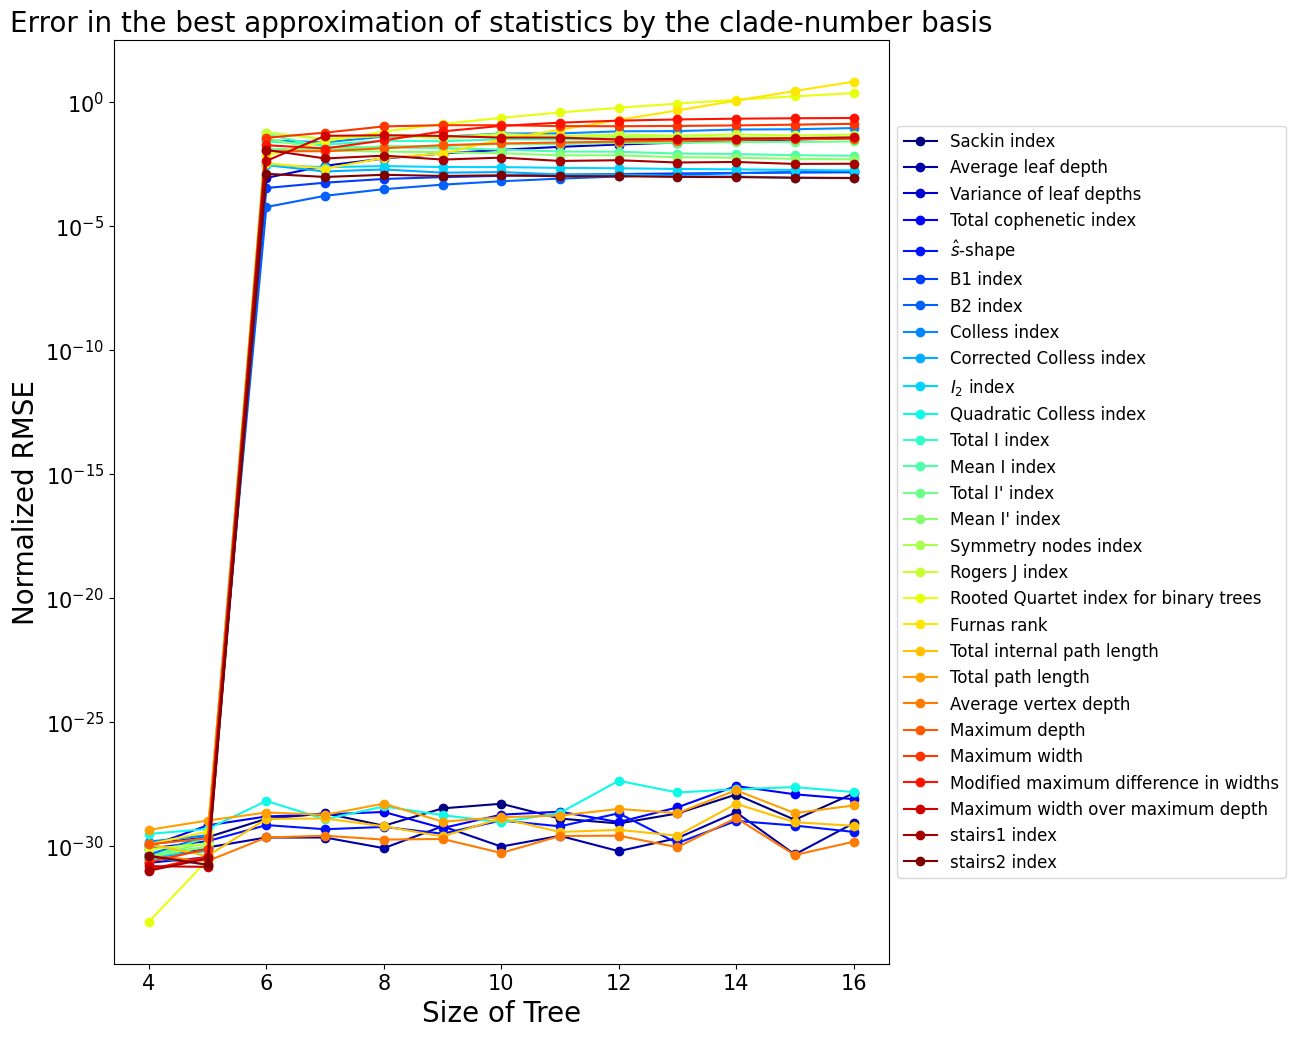

In [23]:
# Now plot the residuals
colors = plt.cm.jet(np.linspace(0,1,len(index_names)))

plt.figure(figsize=(10, 12))
for i in range(len(index_names)):
    plt.semilogy(range(k0, n+1), clade_residuals[:, i], 'o-', label=index_names[i], color=colors[i])
plt.xlabel('Size of Tree', fontsize = 20)
plt.ylabel('Normalized RMSE', fontsize = 20)
plt.legend(index_names)
# Move legend to far right
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12)
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)
plt.title('Error in the best approximation of statistics by the clade-number basis', fontsize = 20)
plt.savefig(os.path.join(parent_dir, 'plots', 'clade_basis_projection_residuals.png'), bbox_inches='tight', dpi=300)
plt.show()

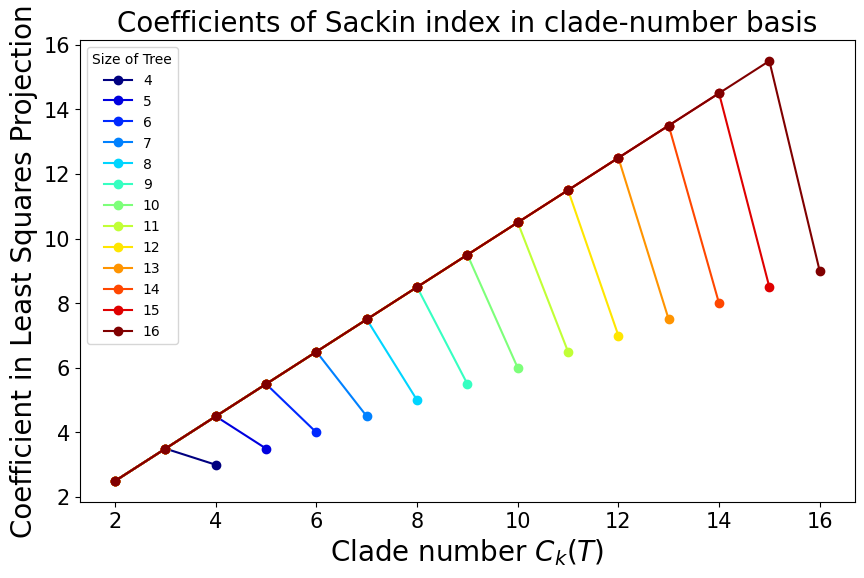

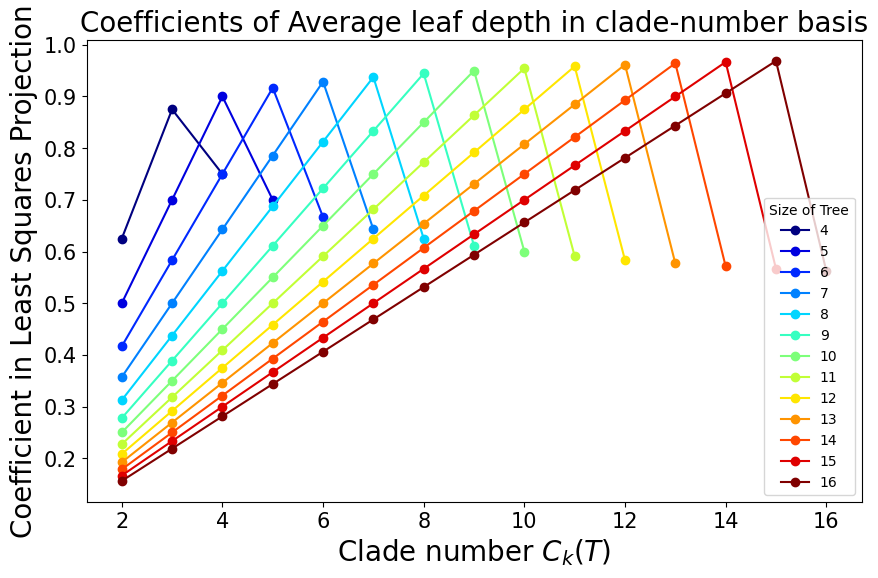

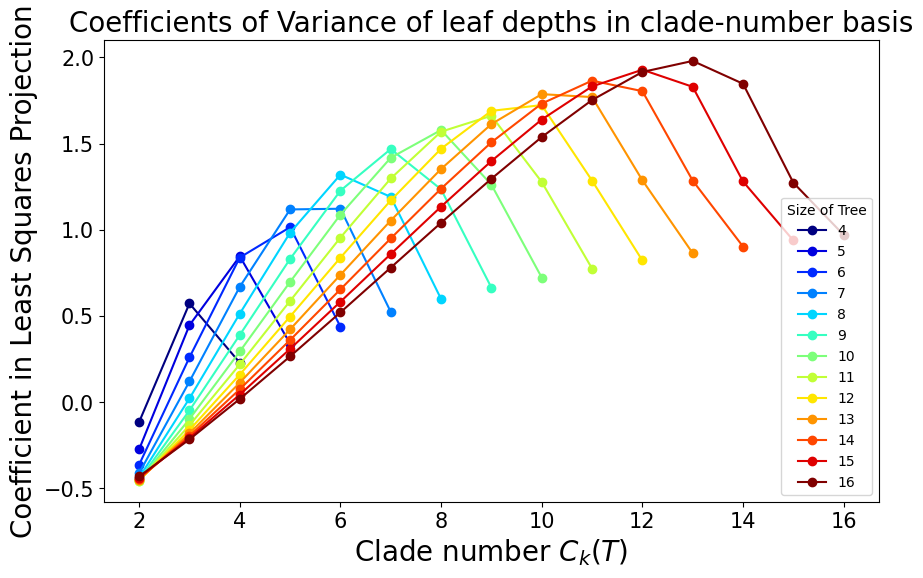

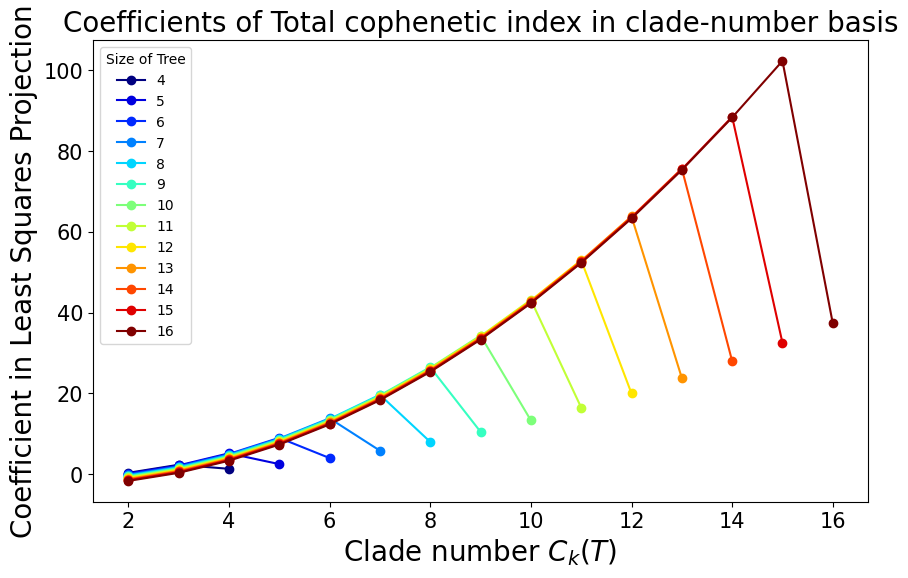

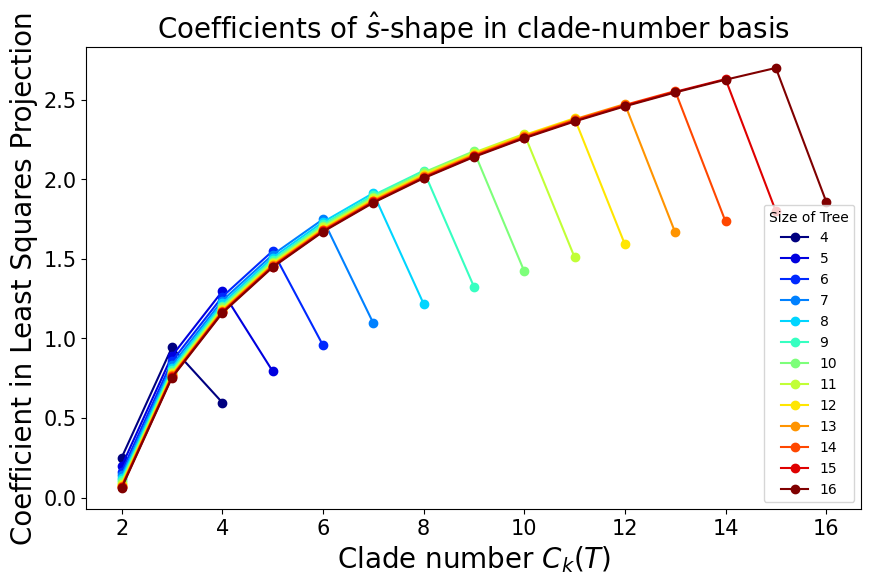

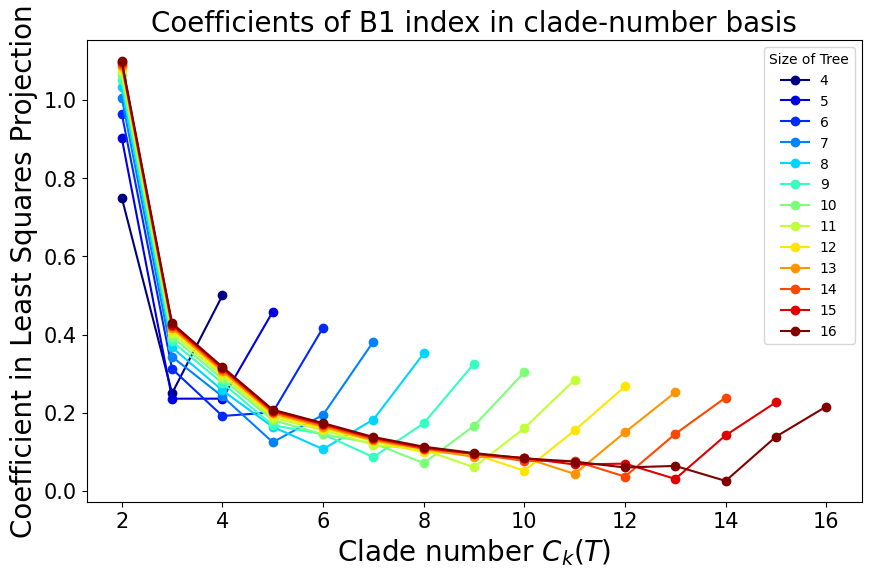

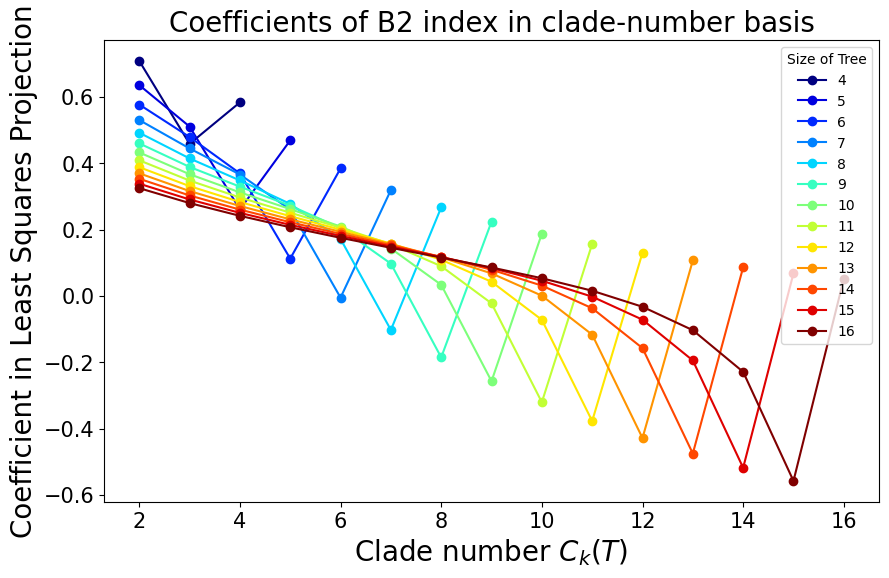

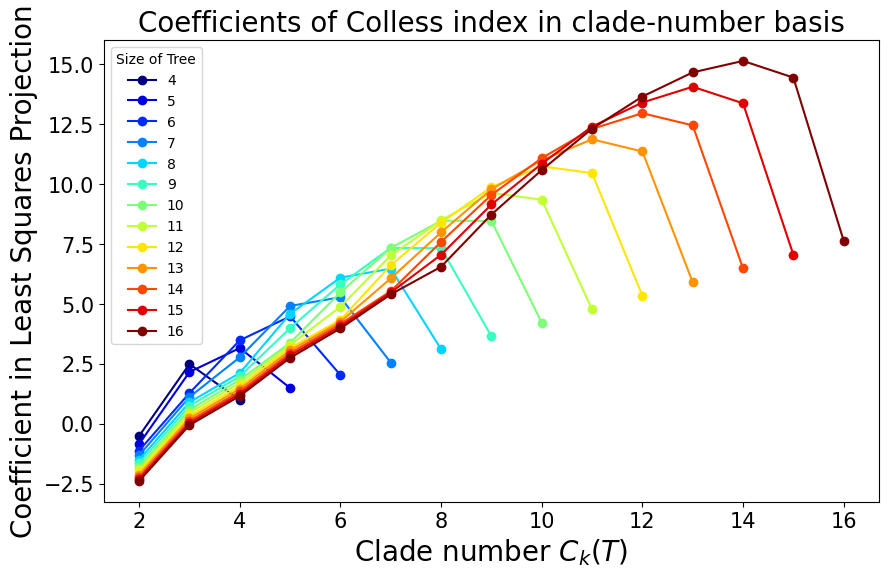

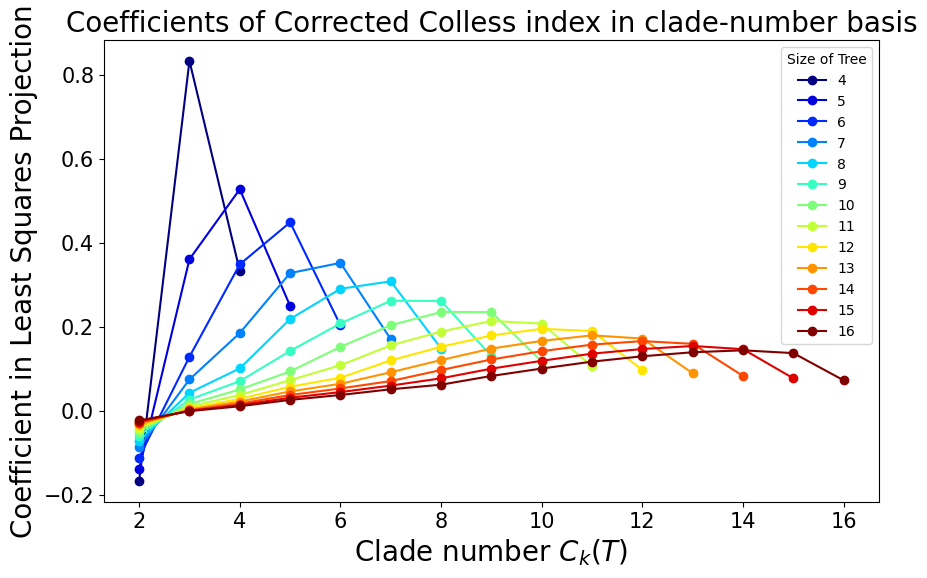

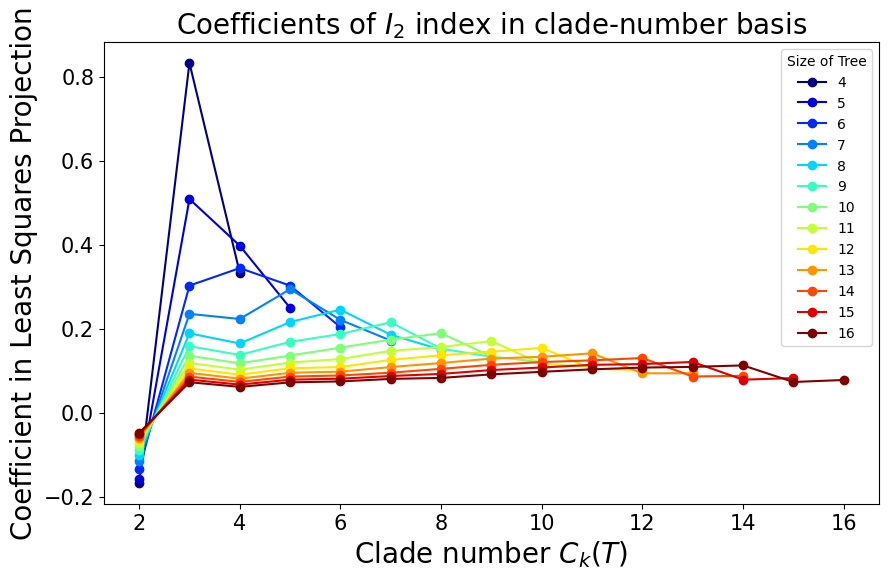

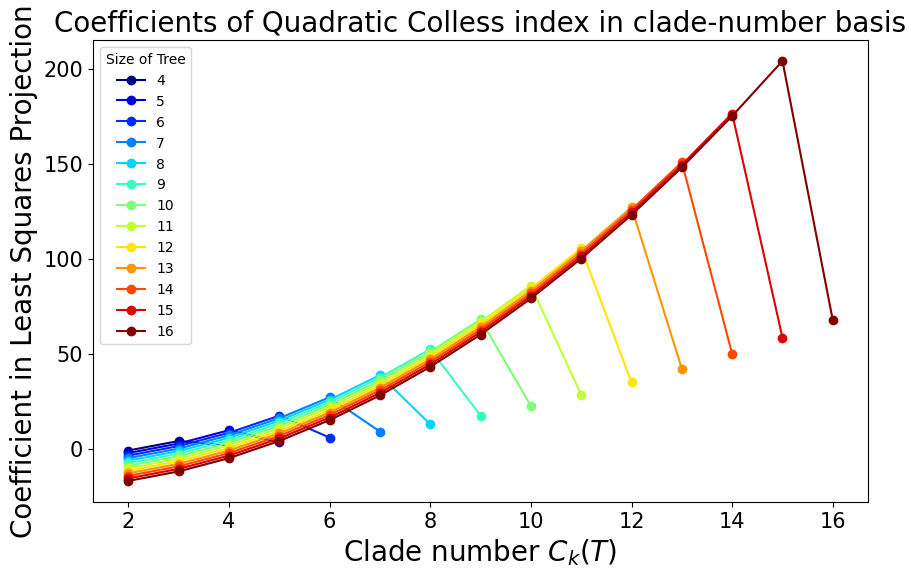

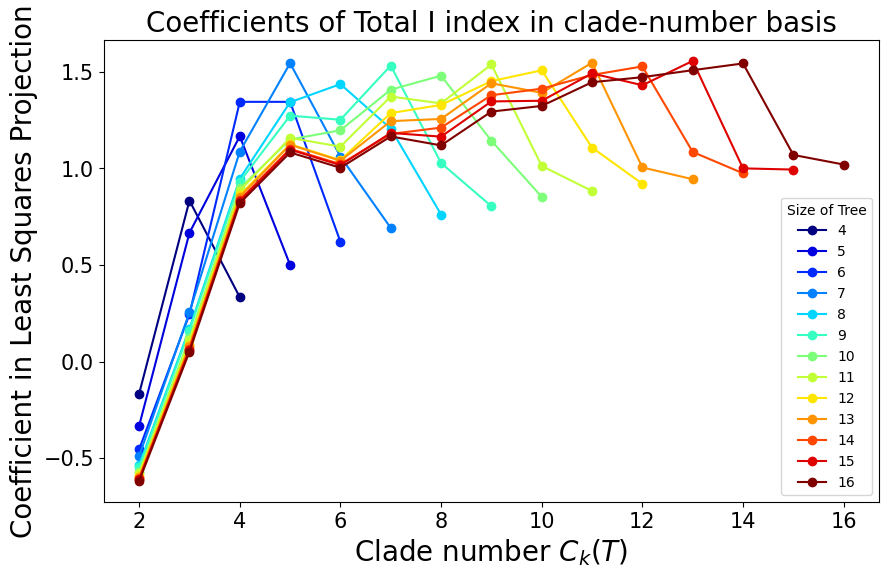

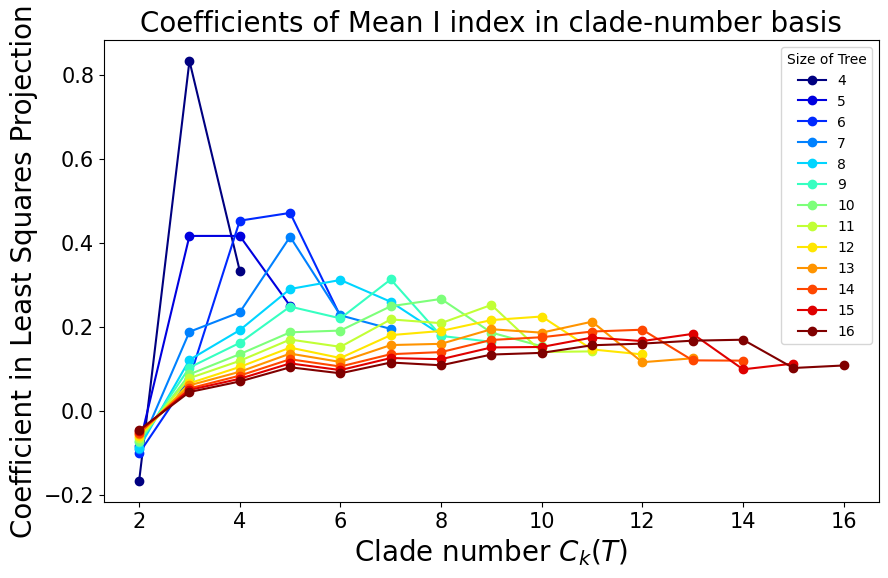

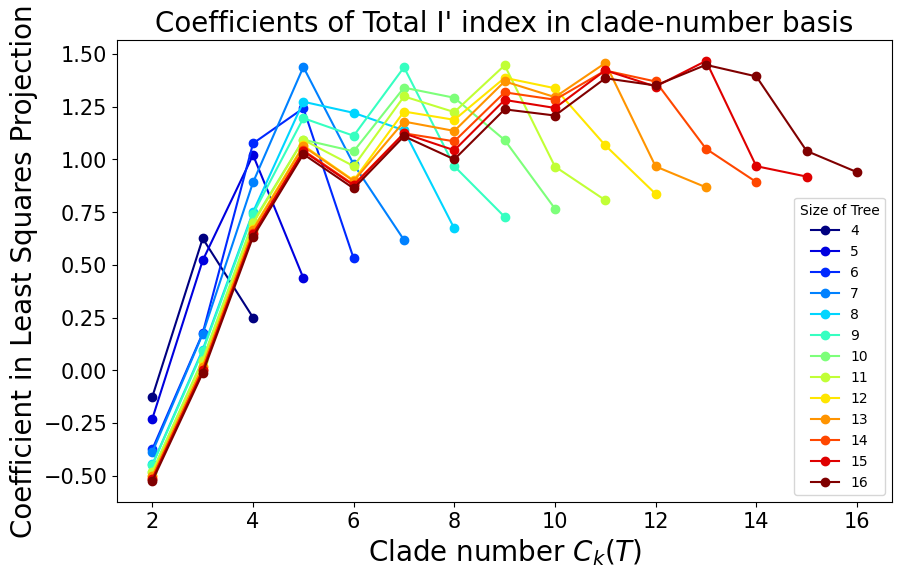

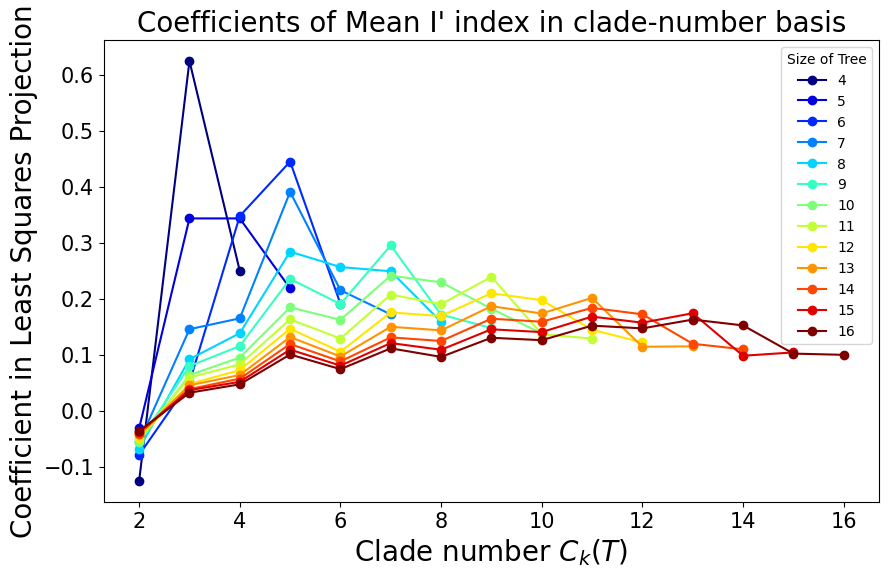

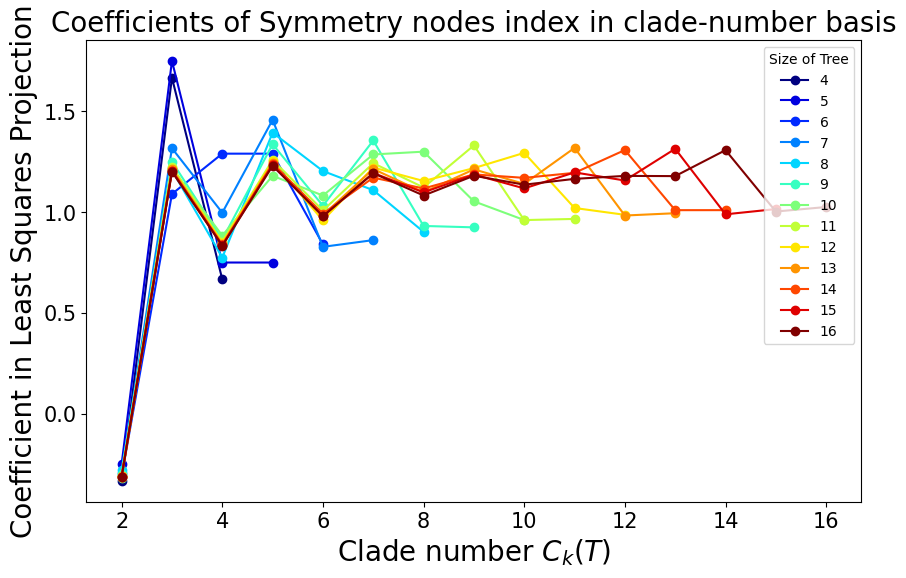

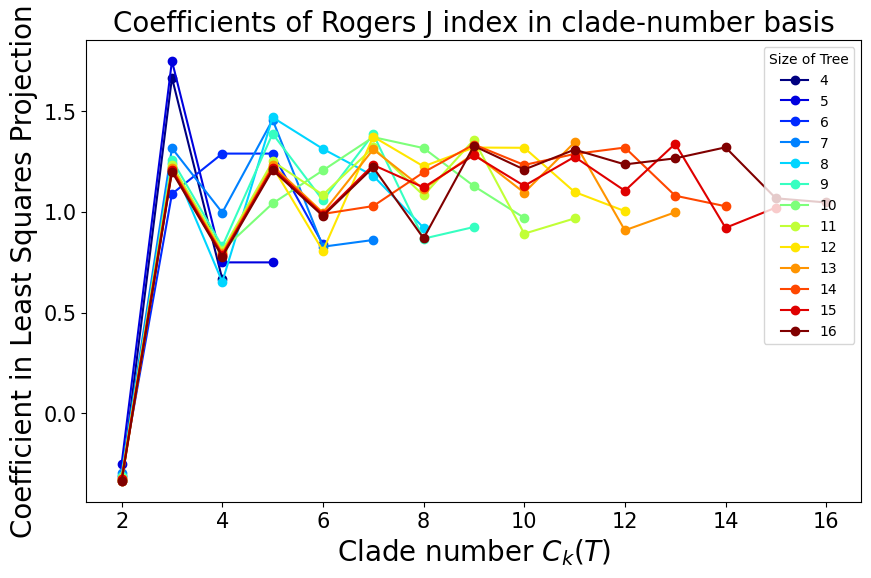

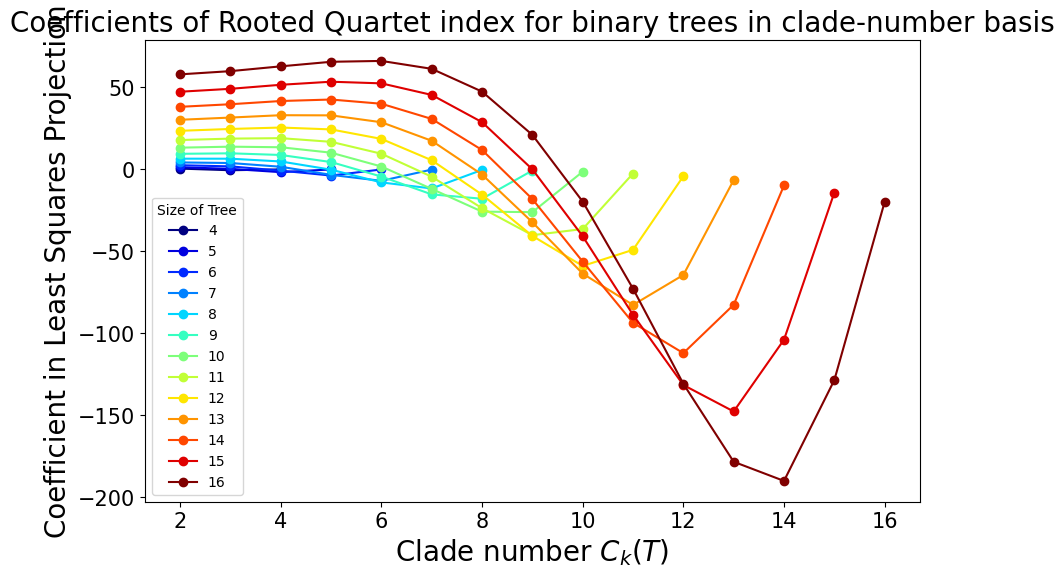

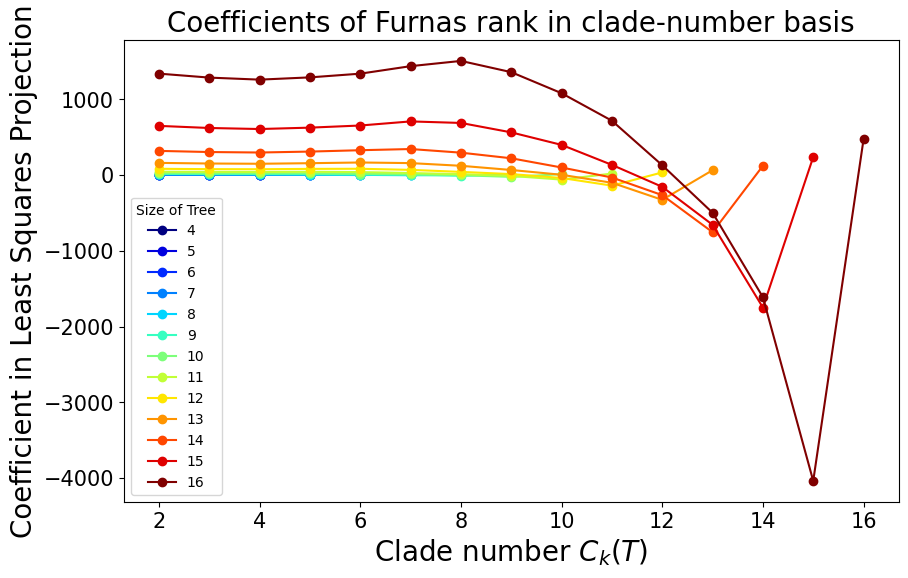

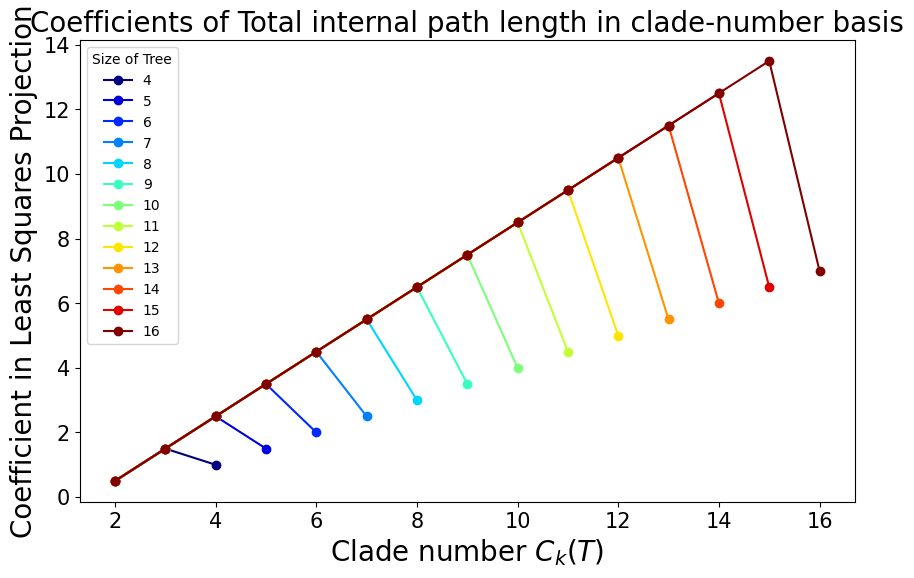

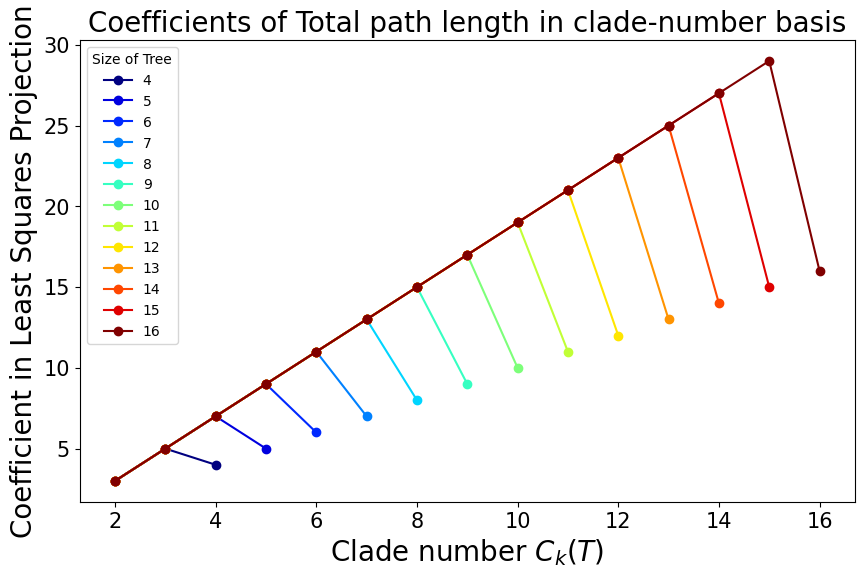

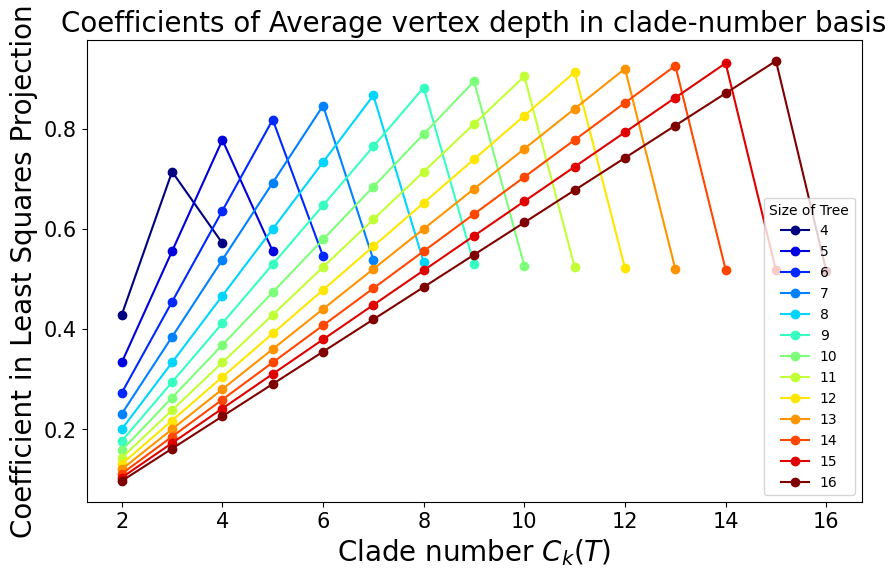

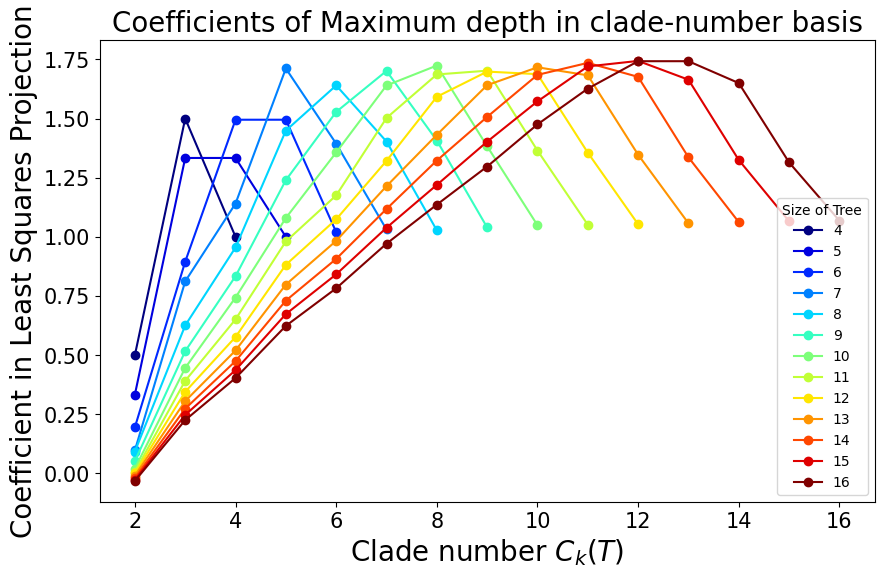

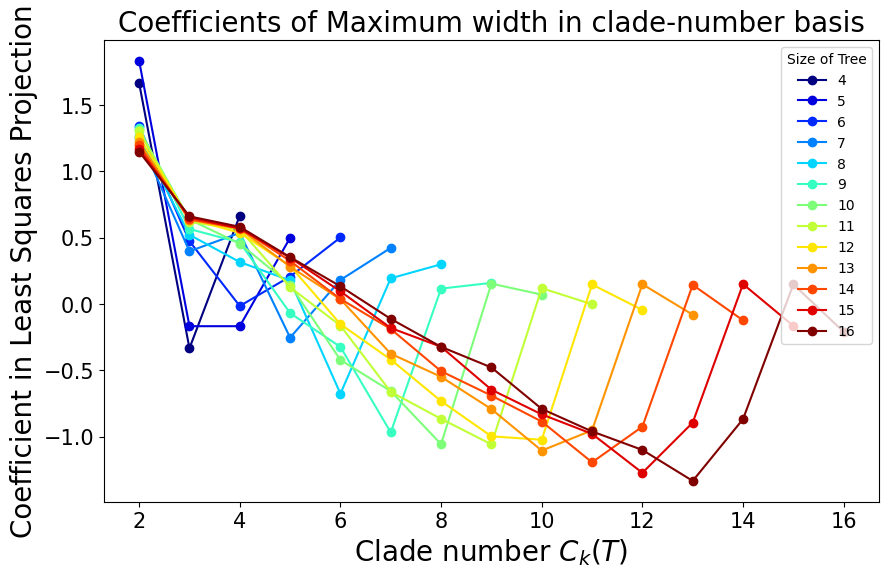

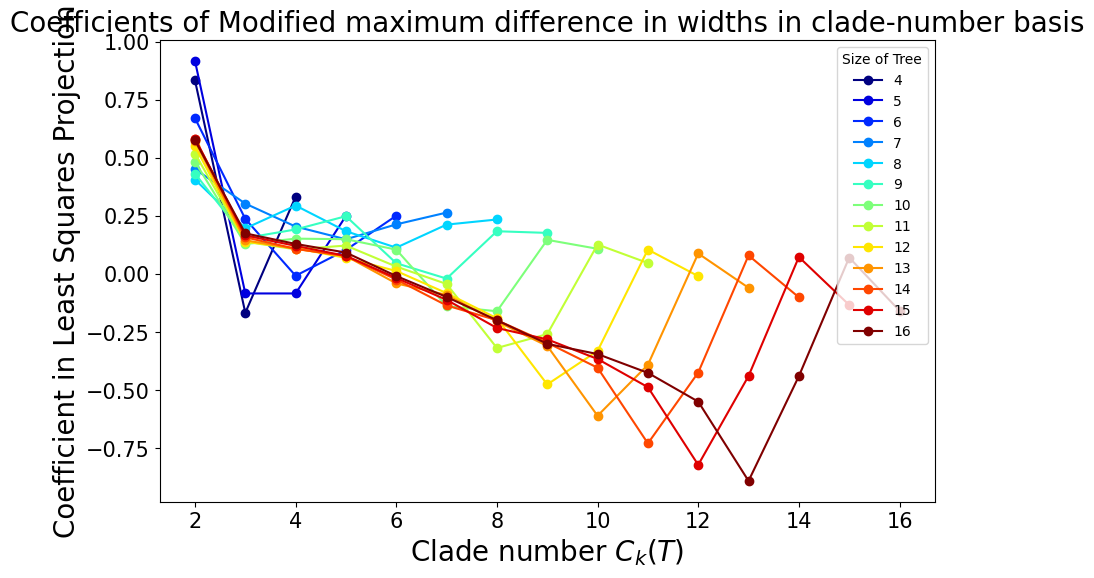

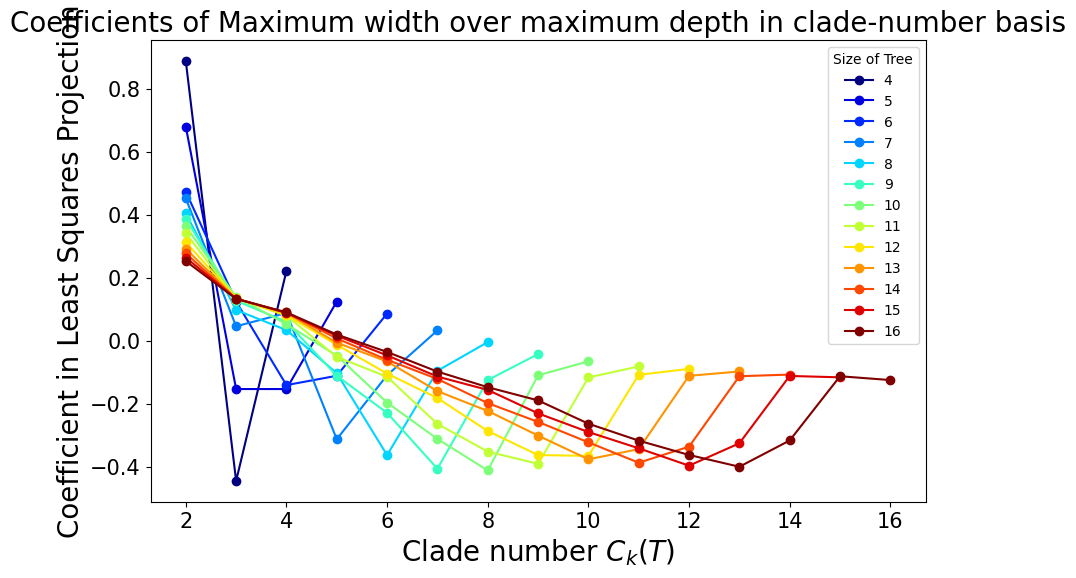

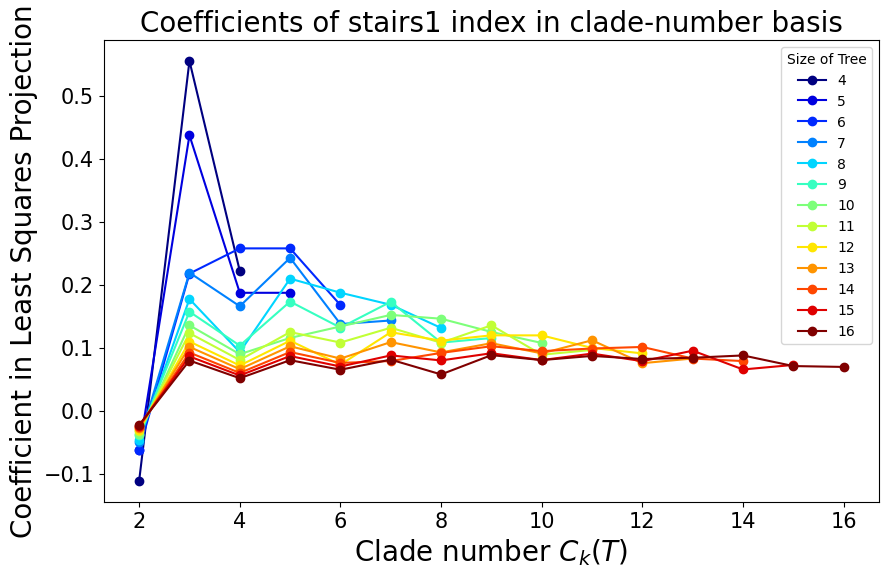

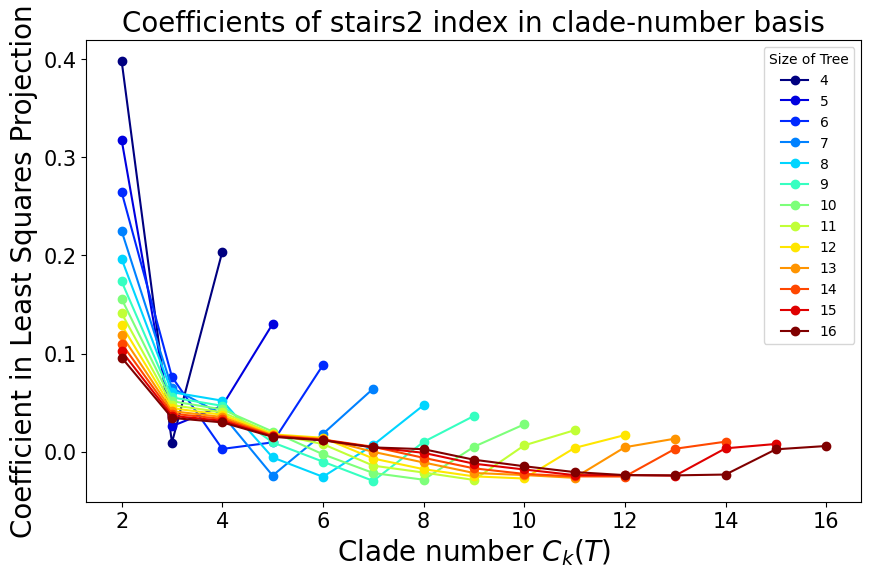

In [30]:
# Let's see the patterns in the coefficients for the clade numbers for every index
colors = plt.cm.jet(np.linspace(0,1,n-k0+1))
for index in clade_regression_results.keys():
    res = clade_regression_results[index]
    plt.figure(figsize=(10, 6))
    for k in range(k0, n+1):
        plt.plot(range(2, k+1), res[k-k0], 'o-', label=k, color=colors[k-k0])
    plt.xlabel('Clade number $C_k(T)$', fontsize = 20)
    plt.ylabel('Coefficient in Least Squares Projection', fontsize = 20)
    plt.title('Coefficients of ' + index + ' in clade-number basis', fontsize = 20)
    plt.xticks(fontsize = 15)
    plt.yticks(fontsize = 15)

    plt.legend(title="Size of Tree")

    plt.show()


In [68]:
def plot_index_coefficients(clade_regression_results, indices, n):
    plt.figure(figsize=(10, 6))
    colors = plt.cm.jet(np.linspace(0, 1, len(indices)))

    for i, index in enumerate(indices):
        res = clade_regression_results[index]
        plt.plot(range(2, n+1), res[-1], 'o-', label=index, color=colors[i])

    plt.xlabel('Clade number $C_r(T)$', fontsize = 20)
    plt.ylabel('Coefficient $a_r$', fontsize = 20)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 15)

    plt.xticks(fontsize = 15)
    plt.yticks(fontsize = 15)

    plt.title('Least squares coefficients for clade numbers, $n = 16$', fontsize = 20)
    plt.show()


In [41]:
index_names

['Sackin index',
 'Average leaf depth',
 'Variance of leaf depths',
 'Total cophenetic index',
 '$\\hat{s}$-shape',
 'B1 index',
 'B2 index',
 'Colless index',
 'Corrected Colless index',
 '$I_2$ index',
 'Quadratic Colless index',
 'Total I index',
 'Mean I index',
 "Total I' index",
 "Mean I' index",
 'Symmetry nodes index',
 'Rogers J index',
 'Rooted Quartet index for binary trees',
 'Furnas rank',
 'Total internal path length',
 'Total path length',
 'Average vertex depth',
 'Maximum depth',
 'Maximum width',
 'Modified maximum difference in widths',
 'Maximum width over maximum depth',
 'stairs1 index',
 'stairs2 index']

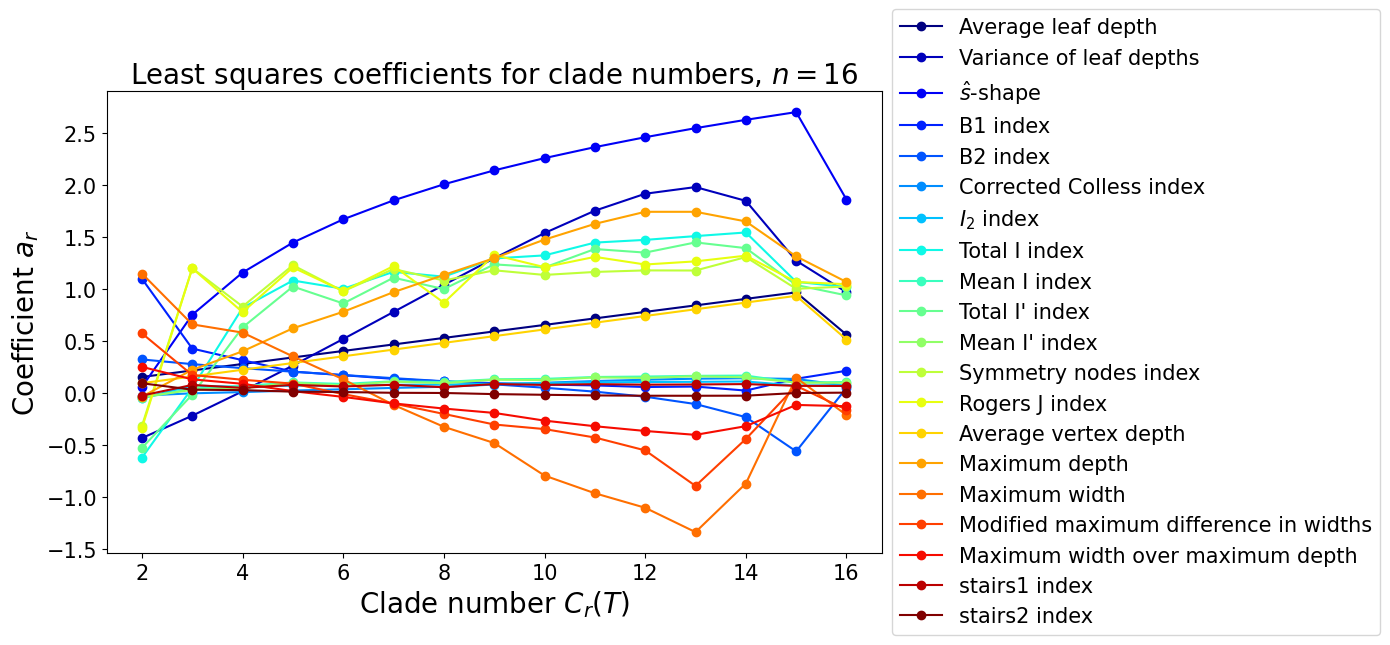

In [46]:
indices_small = [ 'Average leaf depth',
 'Variance of leaf depths',
 '$\\hat{s}$-shape',
 'B1 index',
 'B2 index',
 'Corrected Colless index',
 '$I_2$ index',
 'Total I index',
 'Mean I index',
 "Total I' index",
 "Mean I' index",
 'Symmetry nodes index',
 'Rogers J index',
 'Average vertex depth',
 'Maximum depth',
 'Maximum width',
 'Modified maximum difference in widths',
 'Maximum width over maximum depth',
 'stairs1 index',
 'stairs2 index']

plot_index_coefficients(clade_regression_results, indices_small, n)

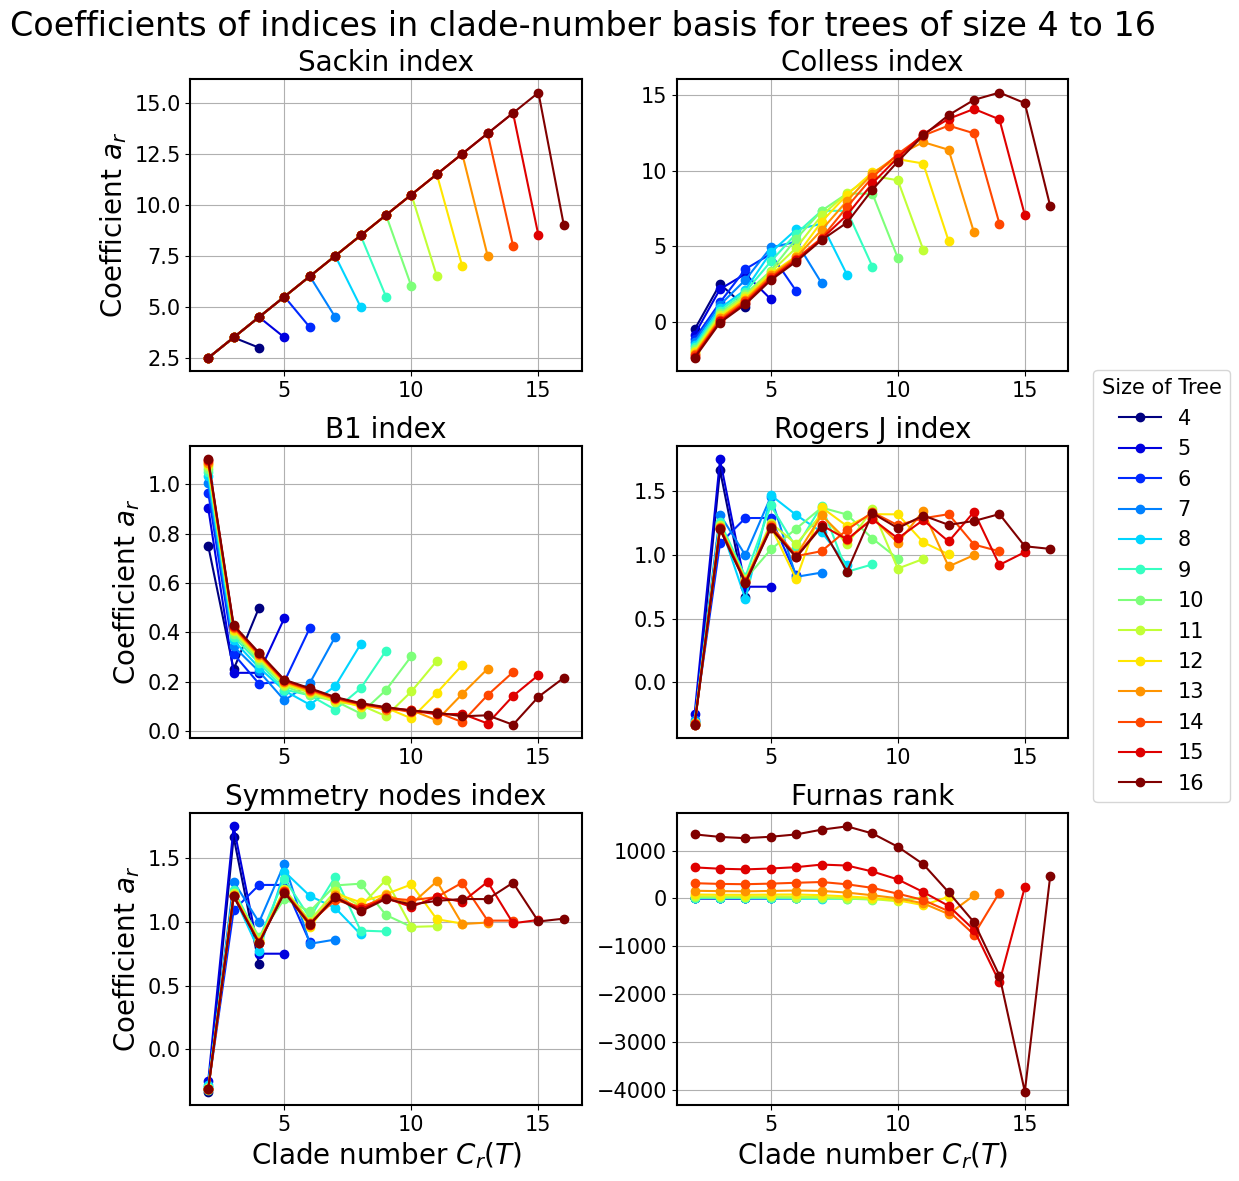

In [66]:
indices = ['Sackin index', 'Colless index', 'B1 index', 'Rogers J index', 'Symmetry nodes index', 'Furnas rank']

# Make a plot with 6 subplots, one for the plot of the coefficients of all sizes for each index
fig, axs = plt.subplots(3, 2, figsize=(10, 12))
k0 = 4
colors = plt.cm.jet(np.linspace(0,1,n-k0+1))

for i, index in enumerate(indices):
    row = i // 2
    col = i % 2

    res = clade_regression_results[index]
    axs[row, col]

    for k in range(k0, n+1):
        axs[row, col].plot(range(2, k+1), res[k-k0], 'o-', label=k, color=colors[k-k0])
    
    if row == 2:
        axs[row, col].set_xlabel('Clade number $C_r(T)$', fontsize = 20)
    if col == 0:
        axs[row, col].set_ylabel('Coefficient $a_r$', fontsize = 20)
    axs[row, col].set_title(index, fontsize = 20)
    axs[row, col].tick_params(axis='both', which='major', labelsize=15)
    axs[row, col].grid(True)

# Make an overall legend for the figure
handles, labels = axs[0, 0].get_legend_handles_labels()
legend = fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1, 0.5), title="Size of Tree", fontsize=15)
legend.get_title().set_fontsize(15)

# Overall title for the figure
plt.suptitle('Coefficients of indices in clade-number basis for trees of size 4 to 16', fontsize=24)

# Add boxes around each subplot, including the title and axes labels
for ax in axs.flat:
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.5)
plt.subplots_adjust(hspace=0.3, wspace=0.3)

plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'clade_basis_coefficients_6_indices.png'), bbox_inches='tight', dpi=300)
plt.show()

In [24]:
# Let's do the same things for the daughter number basis
# Next, for all k=4,...,16, we use least squares to find approximate solution and track residual error for each index

k0 = 4
daughter_residuals = np.zeros((n-k0 + 1, len(index_names)))
daughter_regression_results = {name: [] for name in index_names}

for k in range(k0, n+1):

    _, daughter_numbers, balance_indices, weights = trees.get_data(k)

    daughter_numbers = np.array(daughter_numbers)

    balance_indices = pd.DataFrame(balance_indices, columns=all_index_names)
    # drop Colijn-Plazzatto index
    balance_indices = balance_indices.drop(columns=['Colijn-Plazzotta rank'])
    weights = np.array(weights)

    # weight the data by weights before performing least squares
    W = np.sqrt(np.diag(weights))
    Bw = np.dot(W, balance_indices.values)
    Dw = np.dot(W, daughter_numbers)

    for i in range(len(index_names)):
        # Project each balance index onto the clade number axis
        X = la.lstsq(Dw, Bw[:, i])[0]
        daughter_regression_results[index_names[i]].append(X)
        B_proj = np.dot(Dw, X)
        residual = np.sum((B_proj - Bw[:, i])**2)

        # To compare residuals across indices, we divide by the magnitude of the balance index
        residual /= la.norm(Bw[:, i])
        daughter_residuals[k-k0, i] = residual


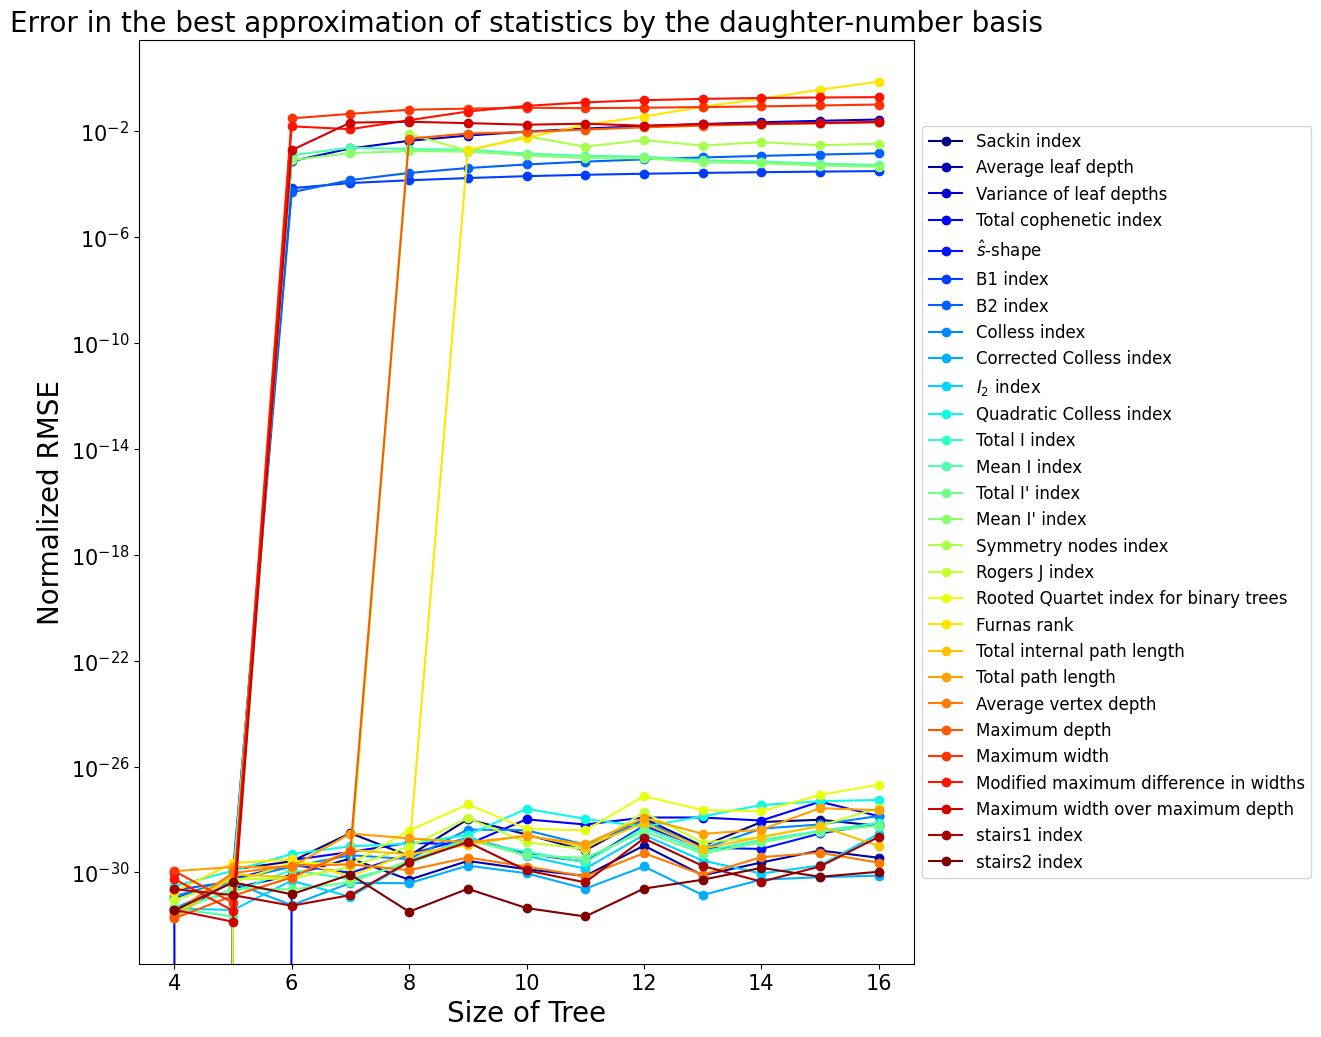

In [25]:
# Now plot the residuals
colors = plt.cm.jet(np.linspace(0,1,len(index_names)))

plt.figure(figsize=(10, 12))
for i in range(len(index_names)):
    plt.semilogy(range(k0, n+1), daughter_residuals[:, i], 'o-', label=index_names[i], color=colors[i])
plt.xlabel('Size of Tree', fontsize = 20)
plt.ylabel('Normalized RMSE', fontsize = 20)
plt.legend(index_names)
# Move legend to far right
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12)
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)
plt.title('Error in the best approximation of statistics by the daughter-number basis', fontsize = 20)
plt.savefig(os.path.join(parent_dir, 'plots', 'daughter_basis_projection_residuals.png'), bbox_inches='tight', dpi=300)
plt.show()

In [29]:
for i in range(daughter_residuals.shape[1]):
    if daughter_residuals[-1,i] > 1e-20:
        print(f"Index {index_names[i]} has a non-zero residual for the largest tree size.")

Index Variance of leaf depths has a non-zero residual for the largest tree size.
Index B1 index has a non-zero residual for the largest tree size.
Index B2 index has a non-zero residual for the largest tree size.
Index Mean I index has a non-zero residual for the largest tree size.
Index Mean I' index has a non-zero residual for the largest tree size.
Index Symmetry nodes index has a non-zero residual for the largest tree size.
Index Furnas rank has a non-zero residual for the largest tree size.
Index Maximum depth has a non-zero residual for the largest tree size.
Index Maximum width has a non-zero residual for the largest tree size.
Index Modified maximum difference in widths has a non-zero residual for the largest tree size.
Index Maximum width over maximum depth has a non-zero residual for the largest tree size.


We observe that we have successfully identified the 11 indices in our paper (not including Colijn-Plazzotta rank) which cannot be represented by the daughter-number basis